# Домашнее задание «Работа с переменными»
## Разведочный анализ данных (EDA) для улучшения линейной регрессии на датасете California Housing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AngryAlexQA/VarData/blob/main/VarData_California_Housing_EDA.ipynb)

**Автор:** Александра Бужор
**Цель:** улучшить метрики RMSE и R² модели линейной регрессии за счёт работы с данными — проверки пропусков, анализа распределений, корреляций, выбросов и математических преобразований признаков.
**Датасет:** `sklearn.datasets.fetch_california_housing`, 20 640 районов (блок-групп) Калифорнии по данным переписи 1990 г.
**Целевая переменная:** `MedHouseVal` — медианная стоимость дома в районе, в сотнях тысяч долларов.

### План работы
1. Загрузка данных
2. Проверка пропусков
3. Разбиение на обучающую и тестовую выборки (80 / 20)
4. Базовая линейная регрессия — **Модель 1**
5. Распределение целевой переменной
6. Корреляционная матрица и отбор признаков — **Модель 2**
7. Выбросы в оставленных признаках — **Модель 3**
8. Математические преобразования признаков — **Модели 4 и 5**
9. Выводы и сравнение всех моделей
10. Дополнительная проверка на исходной тестовой выборке

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

RANDOM_STATE = 42          # фиксируем случайность — разбиение воспроизводимо
TEST_SIZE = 0.2            # 20 % — тестовая выборка, 80 % — обучающая
TARGET = "MedHouseVal"

# Единый стиль графиков: крупный размер, читаемые шрифты, ненавязчивая сетка
BLUE, ORANGE, GREEN, RED, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#52514e"
plt.rcParams.update({
    "figure.figsize": (15, 6),
    "figure.dpi": 110,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

## 1. Загрузка данных

Загружаем датасет как `pandas.DataFrame` (`as_frame=True`) и выводим его описание `DESCR`.

In [2]:
housing = fetch_california_housing(as_frame=True)
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [3]:
df = housing.frame.copy()
print(f"Размер датасета: {df.shape[0]} строк × {df.shape[1]} столбцов")
df.head()

Размер датасета: 20640 строк × 9 столбцов


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


**Описание признаков**

| Признак | Описание |
|---|---|
| `MedInc` | медианный доход домохозяйств в районе, десятки тысяч долларов |
| `HouseAge` | медианный возраст домов в районе, лет |
| `AveRooms` | среднее число комнат на одно домохозяйство |
| `AveBedrms` | среднее число спален на одно домохозяйство |
| `Population` | население района (блок-группы), человек |
| `AveOccup` | среднее число жильцов на одно домохозяйство |
| `Latitude` | широта центра района |
| `Longitude` | долгота центра района |
| `MedHouseVal` | **целевая переменная** — медианная стоимость дома, сотни тысяч долларов |

**Первые наблюдения по описательной статистике:**
- все 9 столбцов числовые (`float64`), 20 640 объектов;
- у `AveRooms`, `AveBedrms`, `Population` и `AveOccup` максимум на порядки больше медианы (например, `AveOccup`: медиана 2.8 жильца, максимум 1243) — это признак тяжёлых хвостов и выбросов;
- максимум `MedHouseVal` = 5.00001, а максимум `MedInc` = 15.0001 — похоже на искусственное ограничение значений сверху (проверим в п. 5).

## 2. Проверка пропусков

In [6]:
missing = df.isna().sum()
print("Количество пропусков по столбцам:")
print(missing.to_string())
print(f"\nВсего пропусков: {missing.sum()}")
print(f"Полных дубликатов строк: {df.duplicated().sum()}")

# Удаляем строки с пропусками (если они есть)
rows_before = len(df)
df = df.dropna()
print(f"\nСтрок до удаления пропусков: {rows_before}, после: {len(df)}")

Количество пропусков по столбцам:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Всего пропусков: 0
Полных дубликатов строк: 0

Строк до удаления пропусков: 20640, после: 20640


**Вывод:** пропусков и полных дубликатов в данных нет, удалять ничего не потребовалось — работаем со всеми 20 640 объектами.

## 3–4. Разбиение выборки и базовая модель линейной регрессии

Пункты 3 и 4 по заданию повторяются для каждой модели, поэтому оформлены функциями:
- `split_data` — разбиение на обучающую (80 %) и тестовую (20 %) выборки с фиксированным `random_state=42`;
- `fit_and_evaluate` — обучение `LinearRegression` и расчёт метрик на обеих выборках.

**Метрики:**
- **RMSE** (корень из среднеквадратичной ошибки) — типичная ошибка прогноза в единицах целевой переменной: RMSE = 0.5 означает ошибку порядка 50 тыс. $. Чем меньше, тем лучше.
- **R²** (коэффициент детерминации) — доля дисперсии целевой переменной, объяснённая моделью. Чем ближе к 1, тем лучше.

Результаты всех моделей собираются в словарь `results` для итоговой таблицы.

In [7]:
def split_data(data, features, target=TARGET):
    """П. 3: разбиение на обучающую (80 %) и тестовую (20 %) выборки."""
    return train_test_split(
        data[features], data[target], test_size=TEST_SIZE, random_state=RANDOM_STATE
    )


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


results = {}  # метрики всех моделей для итоговой таблицы


def fit_and_evaluate(data, features, model_name, short_name, description):
    """П. 4: обучение линейной регрессии, расчёт RMSE и R² на train и test."""
    X_train, X_test, y_train, y_test = split_data(data, features)
    model = LinearRegression().fit(X_train, y_train)
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)

    row = {
        "Модель": model_name,
        "RMSE train": rmse(y_train, pred_train),
        "R2 train": r2_score(y_train, pred_train),
        "RMSE test": rmse(y_test, pred_test),
        "R2 test": r2_score(y_test, pred_test),
        "Объектов": len(data),
        "Признаков": len(features),
        "Признаки (преобразования)": description,
    }
    results[short_name] = row

    print(model_name)
    print(f"  Обучающая выборка: {len(X_train):>6} объектов | RMSE = {row['RMSE train']:.4f} | R² = {row['R2 train']:.4f}")
    print(f"  Тестовая выборка:  {len(X_test):>6} объектов | RMSE = {row['RMSE test']:.4f} | R² = {row['R2 test']:.4f}")
    return {"model": model, "features": features, "X_test": X_test, "y_test": y_test, "pred_test": pred_test}


def quick_test_score(data, features):
    """Быстрая проверка набора признаков: RMSE и R² на тестовой выборке (без записи в results)."""
    X_train, X_test, y_train, y_test = split_data(data, features)
    pred = LinearRegression().fit(X_train, y_train).predict(X_test)
    return rmse(y_test, pred), r2_score(y_test, pred)

In [8]:
features_all = [col for col in df.columns if col != TARGET]

model_1 = fit_and_evaluate(
    df, features_all,
    model_name="Модель 1. Все исходные признаки",
    short_name="М1. Все признаки",
    description="Все 8 признаков без изменений: " + ", ".join(features_all),
)

print("\nКоэффициенты Модели 1:")
print(pd.Series(model_1["model"].coef_, index=features_all).round(4).to_string())

Модель 1. Все исходные признаки
  Обучающая выборка:  16512 объектов | RMSE = 0.7197 | R² = 0.6126
  Тестовая выборка:    4128 объектов | RMSE = 0.7456 | R² = 0.5758

Коэффициенты Модели 1:
MedInc        0.4487
HouseAge      0.0097
AveRooms     -0.1233
AveBedrms     0.7831
Population   -0.0000
AveOccup     -0.0035
Latitude     -0.4198
Longitude    -0.4337


**Вывод по базовой модели:** на тестовой выборке RMSE = 0.7456 (типичная ошибка ≈ 75 тыс. $), R² = 0.5758 — модель объясняет около 58 % дисперсии стоимости. Метрики на обучающей и тестовой выборках близки (R² 0.6126 и 0.5758), сильного переобучения нет. Это точка отсчёта для дальнейших улучшений.

Обратим внимание на коэффициенты: при `AveRooms` он отрицательный (−0.12), а при `AveBedrms` — большой положительный (+0.78). Содержательно «больше комнат → дешевле» не объяснить — это типичный симптом мультиколлинеарности, к нему вернёмся в п. 6.

## 5. Распределение целевой переменной

In [9]:
y = df[TARGET]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_cap = (y == y.max()).sum()

print(f"Среднее: {y.mean():.3f} | медиана: {y.median():.3f} | стандартное отклонение: {y.std():.3f}")
print(f"Минимум: {y.min():.5f} | максимум: {y.max():.5f}")
print(f"Коэффициент асимметрии (skew): {y.skew():.3f}")
print(f"Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
print(f"Границы выбросов по правилу 1.5·IQR: [{lower:.3f}; {upper:.3f}]")
print(f"Значений выше верхней границы: {(y > upper).sum()} ({(y > upper).mean():.1%})")
print(f"Значений ниже нижней границы: {(y < lower).sum()}")
print(f"Значений, равных максимуму {y.max():.5f}: {n_cap} ({n_cap / len(y):.1%})")

Среднее: 2.069 | медиана: 1.797 | стандартное отклонение: 1.154
Минимум: 0.14999 | максимум: 5.00001
Коэффициент асимметрии (skew): 0.978
Q1 = 1.196, Q3 = 2.647, IQR = 1.451
Границы выбросов по правилу 1.5·IQR: [-0.981; 4.824]
Значений выше верхней границы: 1071 (5.2%)
Значений ниже нижней границы: 0
Значений, равных максимуму 5.00001: 965 (4.7%)


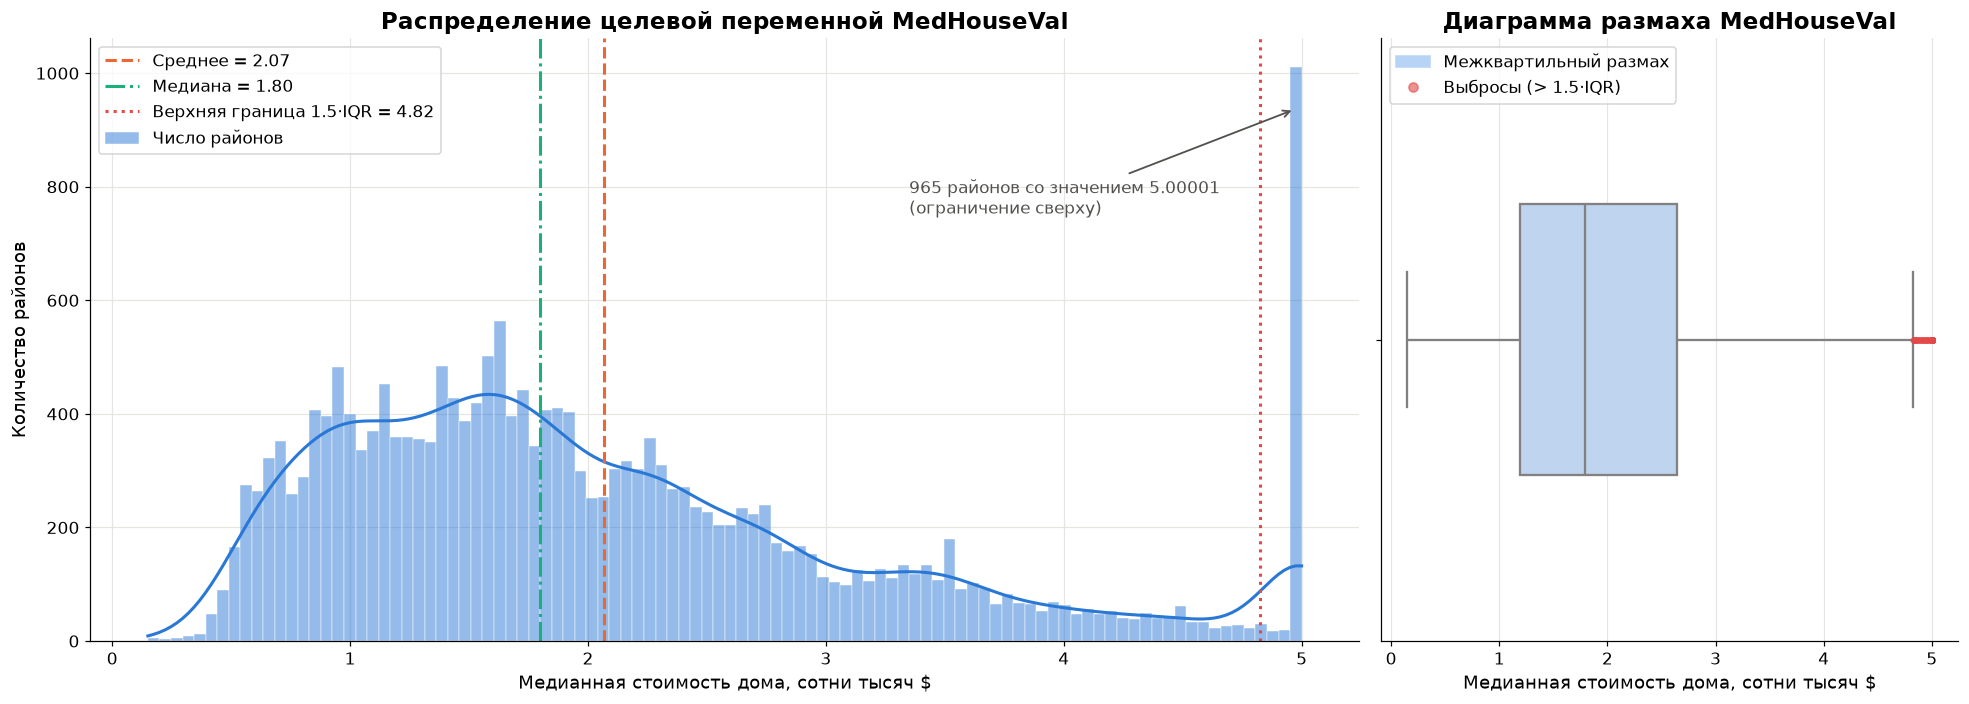

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})

ax = axes[0]
sns.histplot(y, bins=100, kde=True, color=BLUE, edgecolor="white", linewidth=0.3,
             line_kws={"linewidth": 2}, ax=ax, label="Число районов")
ax.axvline(y.mean(), color=ORANGE, lw=2, ls="--", label=f"Среднее = {y.mean():.2f}")
ax.axvline(y.median(), color=GREEN, lw=2, ls="-.", label=f"Медиана = {y.median():.2f}")
ax.axvline(upper, color=RED, lw=2, ls=":", label=f"Верхняя граница 1.5·IQR = {upper:.2f}")
ax.annotate(f"{n_cap} районов со значением 5.00001\n(ограничение сверху)",
            xy=(4.97, n_cap * 0.97), xytext=(3.35, n_cap * 0.78),
            fontsize=11, color=INK, arrowprops=dict(arrowstyle="->", color=INK, lw=1.2))
ax.set_title("Распределение целевой переменной MedHouseVal")
ax.set_xlabel("Медианная стоимость дома, сотни тысяч $")
ax.set_ylabel("Количество районов")
ax.legend(loc="upper left")

ax = axes[1]
sns.boxplot(x=y, color="#b7d3f6", linewidth=1.5, width=0.45, ax=ax,
            flierprops=dict(marker="o", markersize=3, markerfacecolor=RED, markeredgecolor=RED, alpha=0.35))
ax.set_title("Диаграмма размаха MedHouseVal")
ax.set_xlabel("Медианная стоимость дома, сотни тысяч $")
ax.legend(handles=[Patch(color="#b7d3f6", label="Межквартильный размах"),
                   plt.Line2D([], [], marker="o", ls="", color=RED, alpha=0.6, label="Выбросы (> 1.5·IQR)")],
          loc="upper left")

plt.tight_layout()
plt.show()

**Выводы по распределению целевой переменной:**
- Распределение унимодальное и **скошено вправо** (skew ≈ 0.98): у большинства районов стоимость от 1.2 до 2.6 (120–265 тыс. $), дальше тянется длинный хвост дорогих районов. Среднее (2.07) больше медианы (1.80) — ещё одно подтверждение правой асимметрии.
- На правом краю виден **аномальный пик на значении 5.00001** — 965 районов (4.7 %). Это не реальная цена, а **цензурирование** данных: стоимость выше 500 тыс. $ записана как 500 001 $. Истинная стоимость этих районов неизвестна, и линейная модель на них систематически ошибается.
- **Выбросы присутствуют:** по правилу 1.5·IQR выше границы 4.82 находятся 1 071 значение (5.2 %), из них 965 — «потолок» 5.00001. Нижних выбросов нет.
- Решение: эти значения будут удалены в п. 7 вместе с выбросами в признаках.

## 6. Корреляционная матрица

Ячейки матрицы разбиты на **цветные категории по силе связи** (по модулю коэффициента Пирсона, с учётом знака):

| Категория | Значение \|r\| | Цвет |
|---|---|---|
| связи практически нет | < 0.1 | серый |
| слабая | 0.1 – 0.3 | светлый (синий для «−», красный для «+») |
| умеренная | 0.3 – 0.5 | средний |
| заметная | 0.5 – 0.7 | насыщенный |
| сильная | > 0.7 | тёмный |

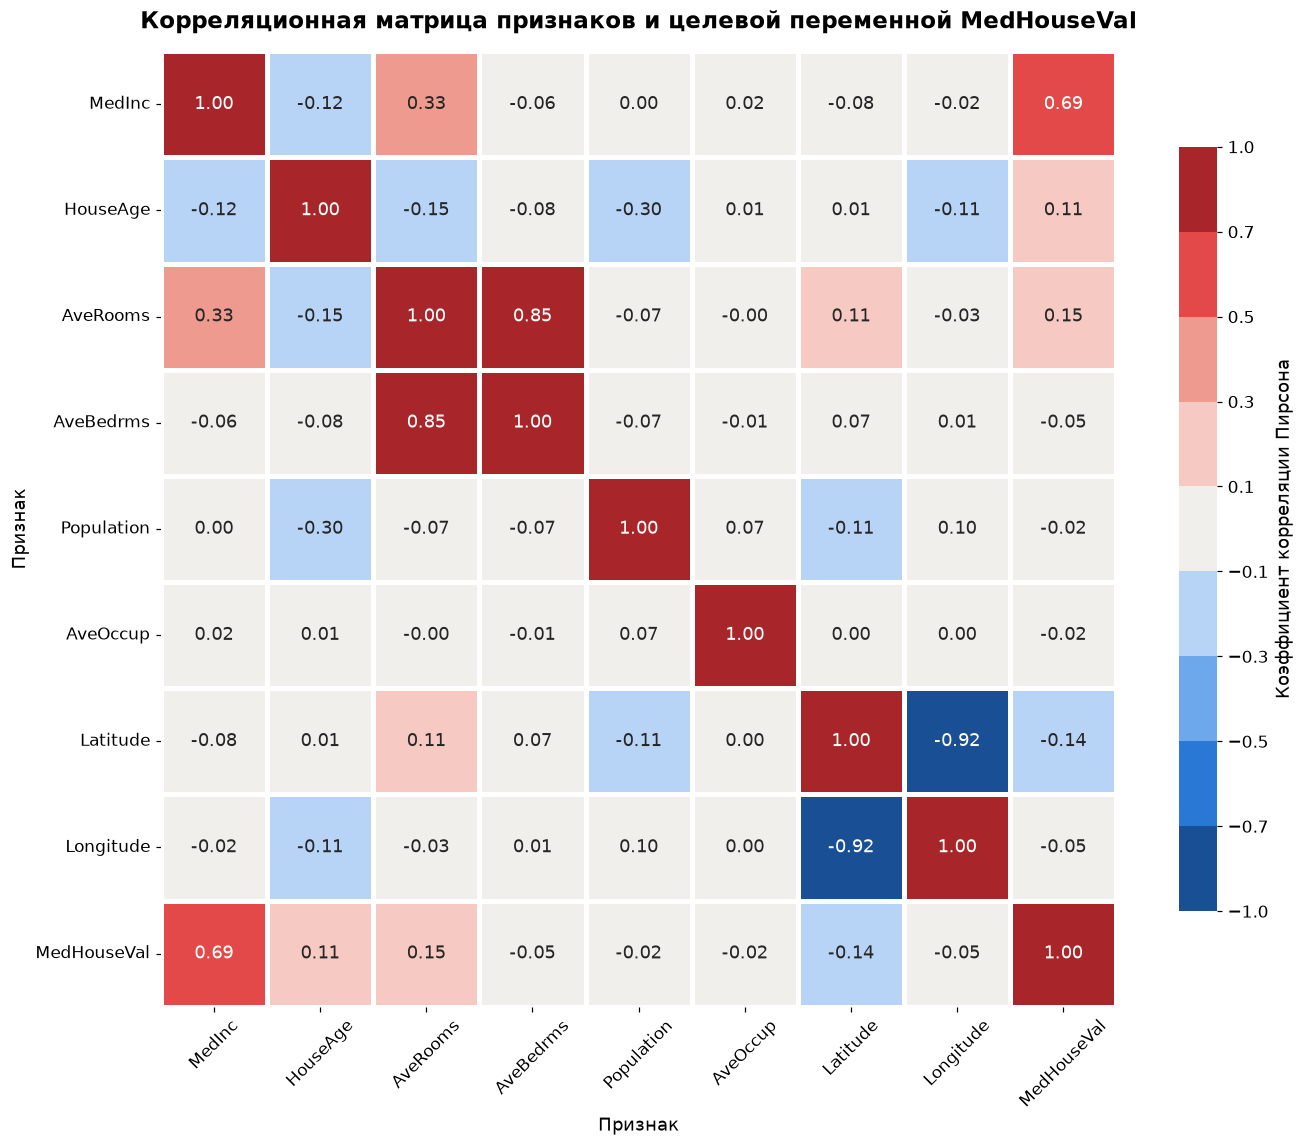

In [11]:
corr = df.corr()

# Дискретная шкала: 9 цветных категорий, синие — отрицательная связь, красные — положительная
bounds = [-1, -0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7, 1]
category_colors = ["#184f95", "#2a78d6", "#6da7ec", "#b7d3f6", "#f0efec",
                   "#f6c9c3", "#ef9a8f", "#e34948", "#a8262a"]
cmap = mcolors.ListedColormap(category_colors)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, norm=norm, square=True,
            linewidths=2, linecolor="white", annot_kws={"size": 12},
            cbar_kws={"ticks": bounds, "shrink": 0.8, "label": "Коэффициент корреляции Пирсона"},
            ax=ax)
ax.set_title("Корреляционная матрица признаков и целевой переменной MedHouseVal", pad=15)
ax.set_xlabel("Признак")
ax.set_ylabel("Признак")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
ax.grid(False)
plt.tight_layout()
plt.show()

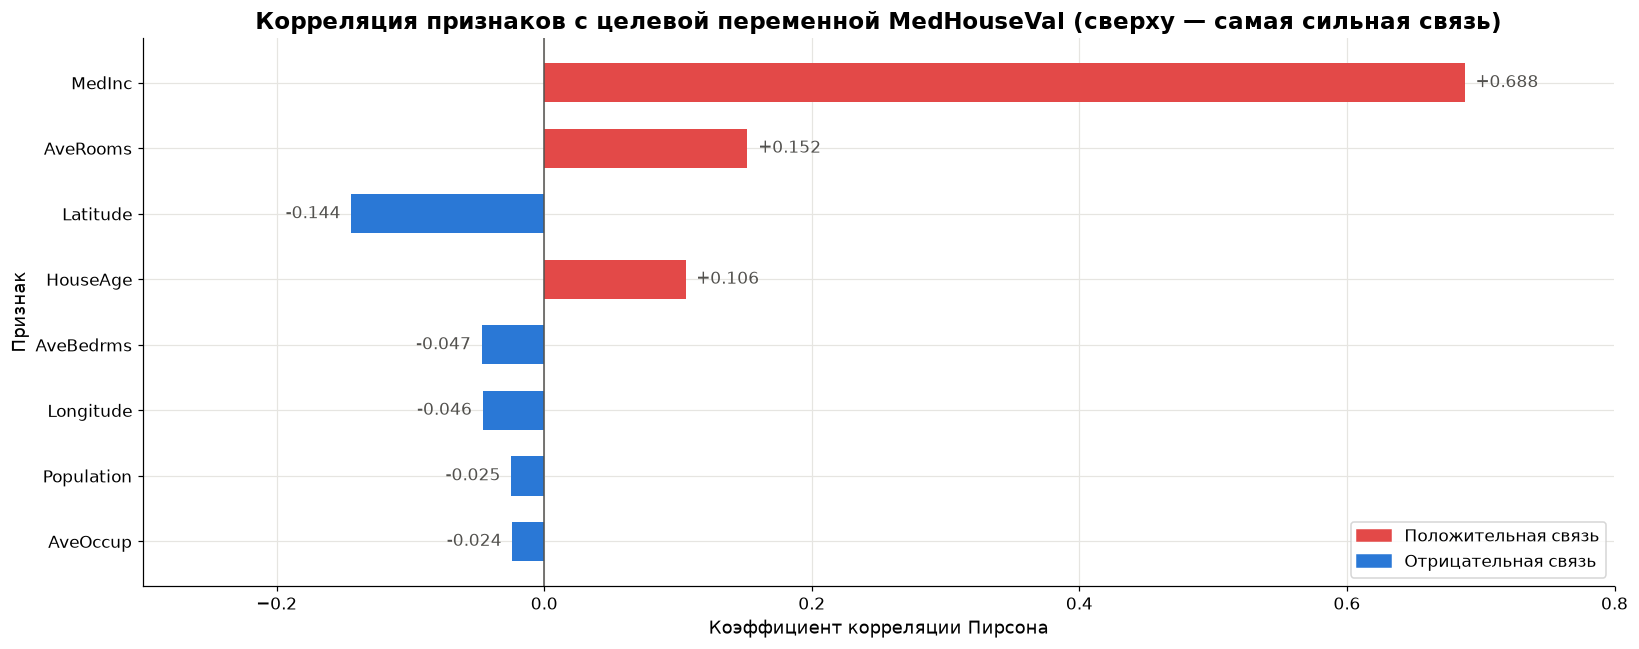

In [12]:
corr_target = corr[TARGET].drop(TARGET).sort_values(key=np.abs)

fig, ax = plt.subplots(figsize=(15, 6))
ax.barh(corr_target.index, corr_target.values, height=0.6,
        color=[RED if v > 0 else BLUE for v in corr_target.values])
for i, v in enumerate(corr_target.values):
    ax.text(v + (0.008 if v >= 0 else -0.008), i, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=11, color=INK)
ax.axvline(0, color=INK, lw=1)
ax.set_xlim(-0.3, 0.8)
ax.set_title("Корреляция признаков с целевой переменной MedHouseVal (сверху — самая сильная связь)")
ax.set_xlabel("Коэффициент корреляции Пирсона")
ax.set_ylabel("Признак")
ax.legend(handles=[Patch(color=RED, label="Положительная связь"),
                   Patch(color=BLUE, label="Отрицательная связь")], loc="lower right")
plt.tight_layout()
plt.show()

У `Longitude` корреляция с целевой переменной почти нулевая, а с `Latitude` — сильная отрицательная (−0.92). Посмотрим на координаты вместе — на карте стоимости жилья:

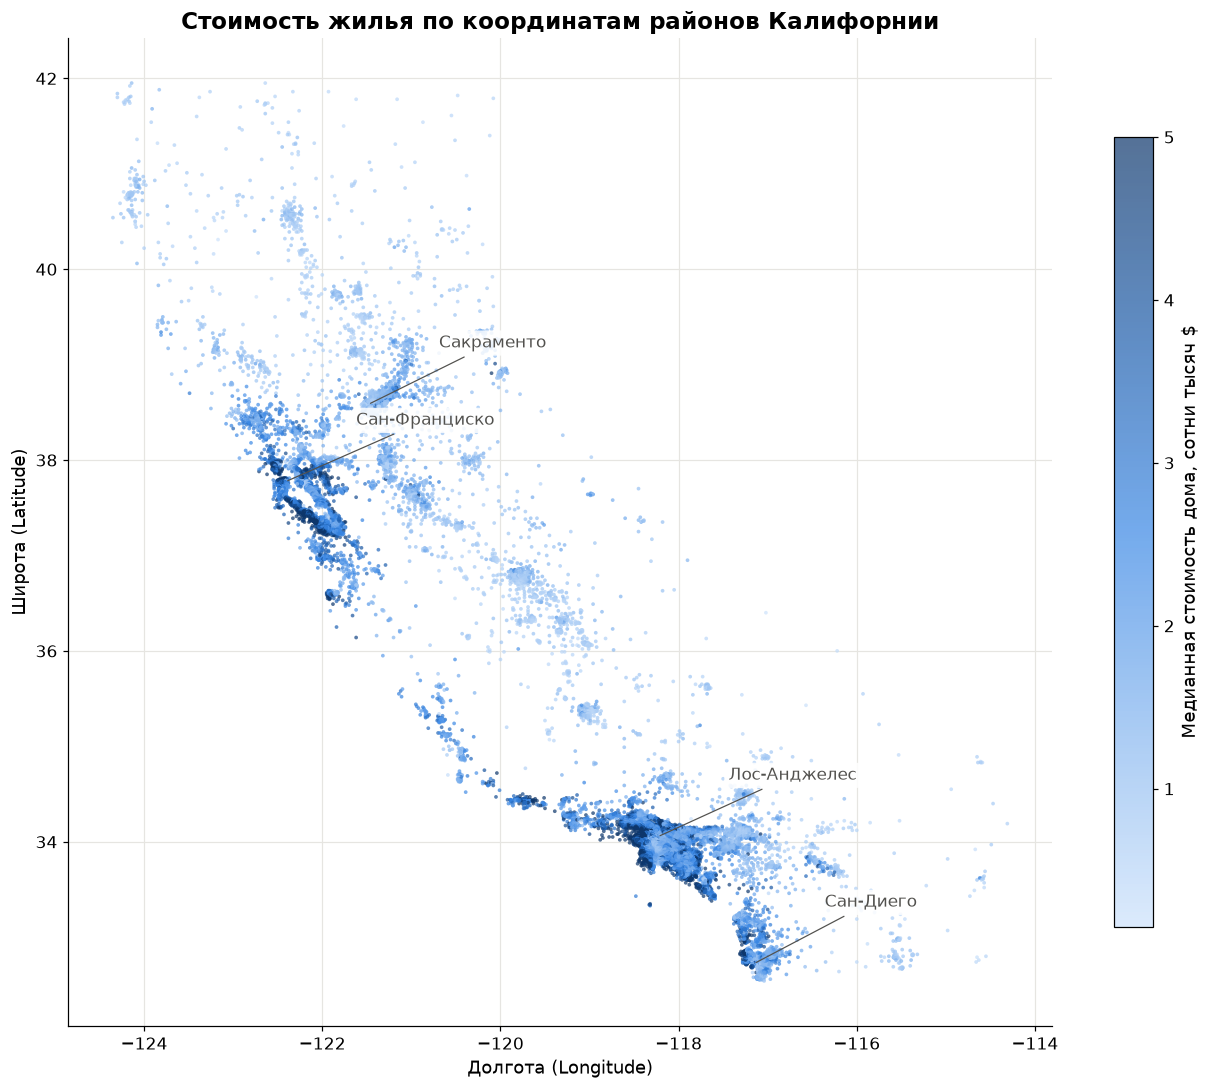

In [13]:
fig, ax = plt.subplots(figsize=(12, 10))
price_cmap = mcolors.LinearSegmentedColormap.from_list(
    "price", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
sc = ax.scatter(df["Longitude"], df["Latitude"], c=df[TARGET], cmap=price_cmap,
                s=6, alpha=0.7, linewidths=0)
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Медианная стоимость дома, сотни тысяч $")
for name, lon, lat in [("Сан-Франциско", -122.42, 37.77), ("Лос-Анджелес", -118.24, 34.05),
                       ("Сан-Диего", -117.16, 32.72), ("Сакраменто", -121.49, 38.58)]:
    ax.annotate(name, xy=(lon, lat), xytext=(lon + 0.8, lat + 0.6), fontsize=11, color=INK,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85),
                arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
ax.set_title("Стоимость жилья по координатам районов Калифорнии")
ax.set_xlabel("Долгота (Longitude)")
ax.set_ylabel("Широта (Latitude)")
plt.tight_layout()
plt.show()

### 6a. Выводы по корреляционной матрице

**Связь признаков с целевой переменной:**
- `MedInc` — **заметная положительная связь** (r = 0.69): чем выше доход жителей района, тем дороже жильё. Это главный предиктор.
- Слабая связь: `AveRooms` (0.15), `Latitude` (−0.14), `HouseAge` (0.11).
- Линейной связи практически нет (\|r\| < 0.05): `AveBedrms` (−0.047), `Longitude` (−0.046), `Population` (−0.025), `AveOccup` (−0.024).

**Связи между признаками (мультиколлинеарность):**
- `AveRooms` ↔ `AveBedrms` = 0.85 — оба признака описывают размер жилья и во многом дублируют друг друга. Именно поэтому в Модели 1 у них получились противоречивые коэффициенты (−0.12 и +0.78).
- `Latitude` ↔ `Longitude` = −0.92 — следствие формы штата: побережье вытянуто с северо-запада на юго-восток. По карте видно, что стоимость определяется **положением района** — близостью к побережью и агломерациям Сан-Франциско, Лос-Анджелеса и Сан-Диего. Это информация, которую несёт **пара координат**, а не каждая по отдельности.
- `Population` ↔ `HouseAge` = −0.30 — умеренная связь, на модель существенно не влияет.

### 6b. Удаление признаков

| Признак | Решение | Обоснование |
|---|---|---|
| `Population` | удалить | связи с целевой практически нет (r = −0.025) |
| `AveOccup` | удалить | связи с целевой практически нет (r = −0.024) |
| `AveBedrms` | удалить | слабая связь с целевой (−0.047) и сильная корреляция с `AveRooms` (0.85); из пары оставляем `AveRooms`, у него связь с целевой сильнее (0.15) |
| `Longitude` | **оставить** | низкая корреляция с целевой обманчива: координаты работают только в паре с `Latitude` (см. карту). Проверим это ниже |
| `MedInc`, `HouseAge`, `AveRooms`, `Latitude` | оставить | есть связь с целевой переменной |

Проверим решение по координатам: как изменится качество, если удалить и `Longitude`.

In [14]:
features_selected = ["MedInc", "HouseAge", "AveRooms", "Latitude", "Longitude"]

variants = {
    "Отобранные признаки (5 шт.)": features_selected,
    "Отобранные без Longitude": ["MedInc", "HouseAge", "AveRooms", "Latitude"],
    "Отобранные без Latitude и Longitude": ["MedInc", "HouseAge", "AveRooms"],
}
check = pd.DataFrame(
    [(name, *quick_test_score(df, feats)) for name, feats in variants.items()],
    columns=["Набор признаков", "RMSE test", "R2 test"],
).set_index("Набор признаков")
check.round(4)

,RMSE test,R2 test
Набор признаков,,
Отобранные признаки (5 шт.),0.7407,0.5814
Отобранные без Longitude,0.8059,0.5043
Отобранные без Latitude и Longitude,0.8117,0.4972


Удаление `Longitude` снижает R² на тесте с 0.58 до 0.50 — решение оставить обе координаты подтверждается: низкая парная корреляция не означает, что признак бесполезен в многомерной модели.

### 6c. Модель 2 — признаки, отобранные по корреляциям

In [15]:
model_2 = fit_and_evaluate(
    df, features_selected,
    model_name="Модель 2. Признаки, отобранные по корреляциям",
    short_name="М2. Отбор по корреляции",
    description="MedInc, HouseAge, AveRooms, Latitude, Longitude — без изменений "
                "(удалены AveBedrms, Population, AveOccup)",
)

Модель 2. Признаки, отобранные по корреляциям
  Обучающая выборка:  16512 объектов | RMSE = 0.7327 | R² = 0.5985
  Тестовая выборка:    4128 объектов | RMSE = 0.7407 | R² = 0.5814


**Вывод:** при сокращении признаков с 8 до 5 метрики на тестовой выборке немного улучшились: RMSE 0.7456 → 0.7407, R² 0.5758 → 0.5814. На обучающей выборке R² снизился (0.6126 → 0.5985) — модель стала проще, разрыв между train и test сократился, то есть переобучение уменьшилось. Улучшение небольшое: удалённые признаки почти не несли полезной *линейной* информации, но и сильно не мешали.

## 7. Выбросы в оставленных признаках

Исследуем на выбросы оставленные признаки и целевую переменную: строим диаграммы размаха и считаем границы по правилу Тьюки:
- **1.5·IQR** — обычные выбросы: значения за пределами [Q1 − 1.5·IQR; Q3 + 1.5·IQR];
- **3·IQR** — экстремальные выбросы.

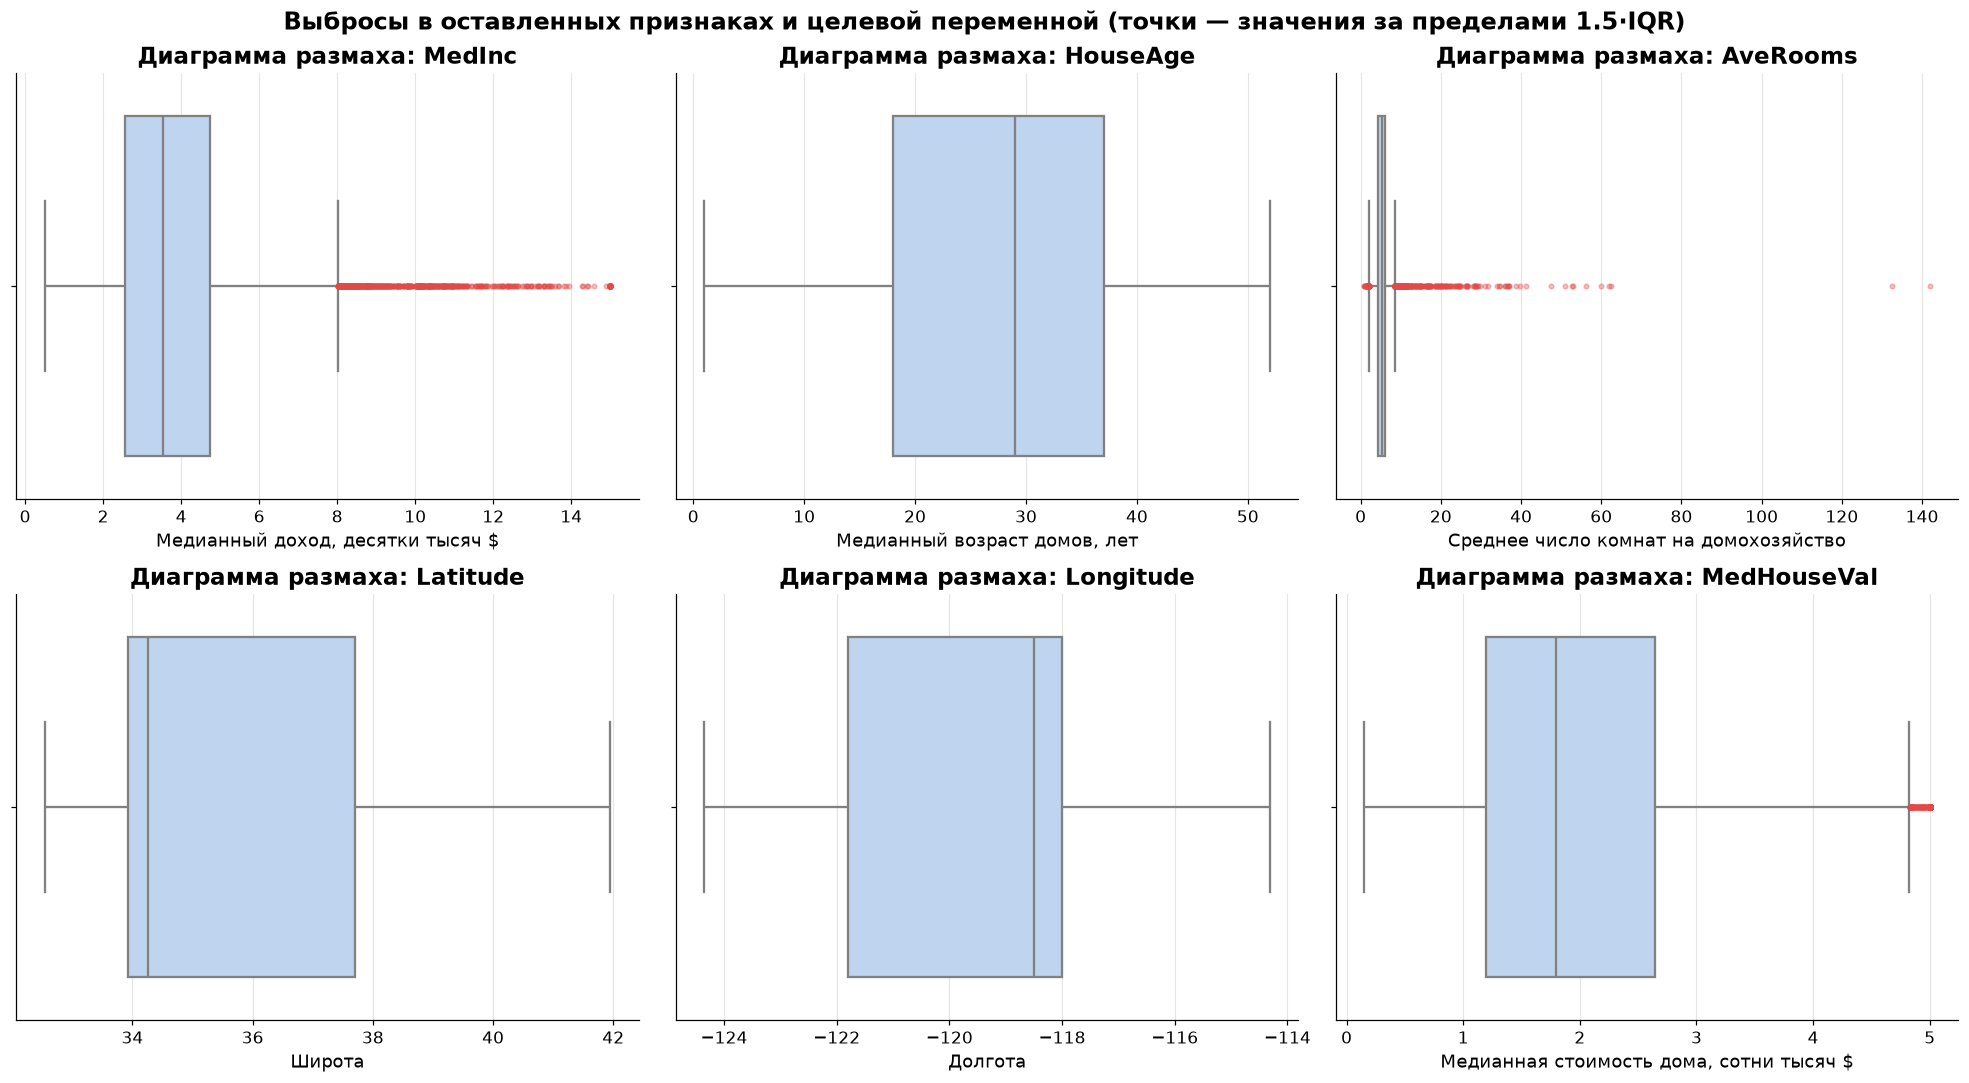

In [16]:
def iqr_bounds(series, k=1.5):
    """Границы выбросов по правилу Тьюки: [Q1 − k·IQR; Q3 + k·IQR]."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


units = {
    "MedInc": "Медианный доход, десятки тысяч $",
    "HouseAge": "Медианный возраст домов, лет",
    "AveRooms": "Среднее число комнат на домохозяйство",
    "Latitude": "Широта",
    "Longitude": "Долгота",
    TARGET: "Медианная стоимость дома, сотни тысяч $",
}
cols_to_check = features_selected + [TARGET]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, cols_to_check):
    sns.boxplot(x=df[col], color="#b7d3f6", linewidth=1.5, ax=ax,
                flierprops=dict(marker="o", markersize=3, markerfacecolor=RED, markeredgecolor=RED, alpha=0.35))
    ax.set_title(f"Диаграмма размаха: {col}")
    ax.set_xlabel(units[col])
fig.suptitle("Выбросы в оставленных признаках и целевой переменной (точки — значения за пределами 1.5·IQR)",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
rows = []
for col in cols_to_check:
    s = df[col]
    lo15, hi15 = iqr_bounds(s, 1.5)
    lo3, hi3 = iqr_bounds(s, 3.0)
    n15 = (~s.between(lo15, hi15)).sum()
    rows.append({
        "Признак": col,
        "Мин": s.min(), "Медиана": s.median(), "Макс": s.max(),
        "Асимметрия": s.skew(),
        "Граница 1.5·IQR": f"[{lo15:.2f}; {hi15:.2f}]",
        "Выбросов 1.5·IQR": n15,
        "% выбросов": 100 * n15 / len(s),
        "Граница 3·IQR": f"[{lo3:.2f}; {hi3:.2f}]",
        "Выбросов 3·IQR": (~s.between(lo3, hi3)).sum(),
    })
outliers_table = pd.DataFrame(rows).set_index("Признак")
outliers_table.round(2)

,Мин,Медиана,Макс,Асимметрия,Граница 1.5·IQR,Выбросов 1.5·IQR,% выбросов,Граница 3·IQR,Выбросов 3·IQR
Признак,,,,,,,,,
MedInc,0.50,3.53,15.00,1.65,[-0.71; 8.01],681,3.30,[-3.98; 11.28],140
HouseAge,1.00,29.00,52.00,0.06,[-10.50; 65.50],0,0.00,[-39.00; 94.00],0
AveRooms,0.85,5.23,141.91,20.70,[2.02; 8.47],511,2.48,[-0.39; 10.89],180
Latitude,32.54,34.26,41.95,0.47,[28.26; 43.38],0,0.00,[22.59; 49.05],0
Longitude,-124.35,-118.49,-114.31,-0.30,[-127.48; -112.33],0,0.00,[-133.17; -106.64],0
MedHouseVal,0.15,1.80,5.00,0.98,[-0.98; 4.82],1071,5.19,[-3.16; 7.00],0


**Анализ выбросов:**
- `HouseAge`, `Latitude`, `Longitude` — выбросов по правилу IQR нет. У `HouseAge` есть «потолок» 52 года (1 273 района), но это значение лежит внутри границ и несёт информацию «дом старше 52 лет», поэтому признак не трогаем.
- `MedHouseVal` — 1 071 выброс выше 4.82, из них 965 — цензурированные значения 5.00001 (см. п. 5). **Удаляем по правилу 1.5·IQR.**
- `AveRooms` — 511 выбросов (2.5 %), максимум 141.9 комнаты на домохозяйство при медиане 5.2. Такие значения не характерны для обычного жилья (курортные и сезонные дома, общежития, малые районы с искажённой статистикой). **Удаляем по правилу 1.5·IQR** — остаются районы с 2.0–8.5 комнаты на домохозяйство.
- `MedInc` — 681 значение выше 8.01 по правилу 1.5·IQR. Но это реальные обеспеченные районы, а доход — главный предиктор: удалив их, мы сузим диапазон и потеряем полезную информацию. Поэтому **удаляем только экстремальные выбросы по правилу 3·IQR** (выше 11.28 — 140 районов), в том числе 51 цензурированное значение 15.0001.

In [18]:
outlier_rules = {TARGET: 1.5, "AveRooms": 1.5, "MedInc": 3.0}   # признак: множитель k для k·IQR

mask = pd.Series(True, index=df.index)
for col, k in outlier_rules.items():
    lo, hi = iqr_bounds(df[col], k)
    col_mask = df[col].between(lo, hi)
    print(f"{col:<12} k = {k}: границы [{lo:.3f}; {hi:.3f}], выбросов {(~col_mask).sum()}")
    mask &= col_mask

df_clean = df.loc[mask].copy()
removed = len(df) - len(df_clean)
print(f"\nУдалено строк (с учётом пересечений): {removed} ({removed / len(df):.1%})")
print(f"Осталось строк: {len(df_clean)}")
print(f"Стандартное отклонение MedHouseVal: до {df[TARGET].std():.3f}, после {df_clean[TARGET].std():.3f}")

MedHouseVal  k = 1.5: границы [-0.981; 4.824], выбросов 1071
AveRooms     k = 1.5: границы [2.023; 8.470], выбросов 511
MedInc       k = 3.0: границы [-3.976; 11.283], выбросов 140

Удалено строк (с учётом пересечений): 1470 (7.1%)
Осталось строк: 19170
Стандартное отклонение MedHouseVal: до 1.154, после 0.952


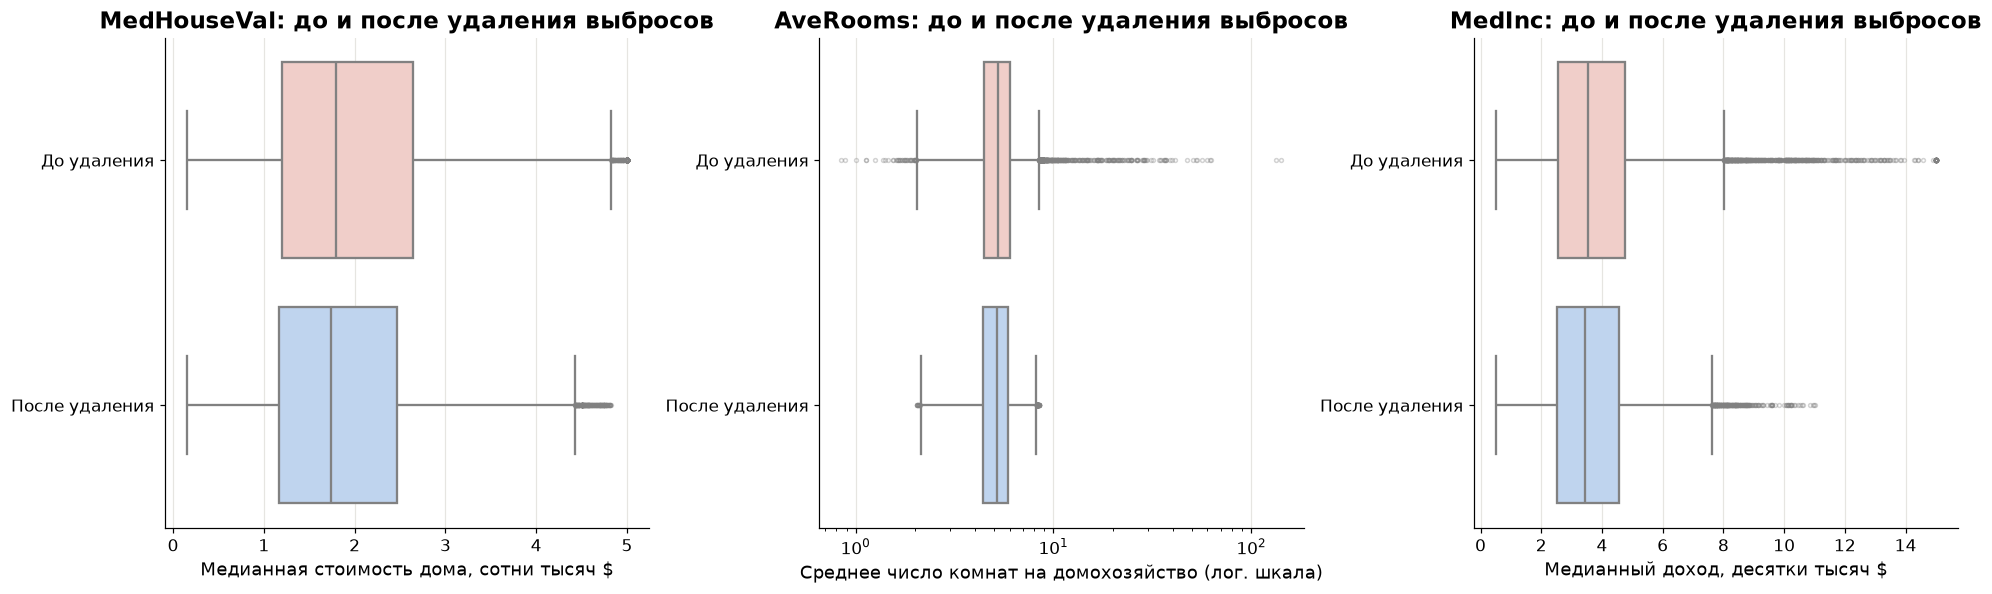

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, col in zip(axes, outlier_rules):
    data_long = pd.concat([
        pd.DataFrame({"value": df[col], "Данные": "До удаления"}),
        pd.DataFrame({"value": df_clean[col], "Данные": "После удаления"}),
    ])
    sns.boxplot(data=data_long, x="value", y="Данные", hue="Данные",
                palette={"До удаления": "#f6c9c3", "После удаления": "#b7d3f6"},
                linewidth=1.5, ax=ax, legend=False,
                flierprops=dict(marker="o", markersize=2.5, alpha=0.35))
    ax.set_title(f"{col}: до и после удаления выбросов")
    ax.set_xlabel(units[col])
    ax.set_ylabel("")
    if col == "AveRooms":
        ax.set_xscale("log")
        ax.set_xlabel(units[col] + " (лог. шкала)")
plt.tight_layout()
plt.show()

На диаграммах «после удаления» снова видны отдельные точки за «усами» — это ожидаемо: квартили пересчитаны по новым данным, и это уже не экстремальные значения, а края нормального распределения.

In [20]:
model_3 = fit_and_evaluate(
    df_clean, features_selected,
    model_name="Модель 3. Отобранные признаки, выбросы удалены",
    short_name="М3. + без выбросов",
    description="MedInc, HouseAge, AveRooms, Latitude, Longitude без изменений; удалены выбросы: "
                "MedHouseVal и AveRooms — по 1.5·IQR, MedInc — по 3·IQR (−1 470 строк)",
)

Модель 3. Отобранные признаки, выбросы удалены
  Обучающая выборка:  15336 объектов | RMSE = 0.6252 | R² = 0.5682
  Тестовая выборка:    3834 объектов | RMSE = 0.6089 | R² = 0.5925


**Вывод:** после удаления выбросов RMSE на тестовой выборке снизился с 0.7407 до 0.6089 (≈ −18 %), R² вырос с 0.5814 до 0.5925.

Важно понимать природу этого улучшения: заметная часть снижения RMSE объясняется тем, что из данных ушли самые дорогие и цензурированные районы, на которых ошибка максимальна, а разброс целевой переменной уменьшился (std 1.154 → 0.952). Задача стала «проще», и тестовая выборка теперь тоже другая. Насколько модель действительно стала лучше, проверим в п. 10 на исходной тестовой выборке.

## 8. Математические преобразования признаков

Выбранные преобразования:

1. **`log(AveRooms)` — логарифм.** Эффект числа комнат убывающий: разница между 2 и 3 комнатами важнее, чем между 7 и 8. Логарифм переводит абсолютные различия в относительные.
2. **`Latitude²`, `Longitude²`, `Latitude·Longitude` — квадраты и произведение координат.** Линейная модель с «голыми» координатами может описать только плоскость с наклоном в одну сторону, а по карте цены растут к побережью, которое идёт по диагонали. Полином 2-й степени от координат позволяет описать изогнутую поверхность цен.
3. **`log(AveOccup)` — возвращаем удалённый признак в логарифмической форме.** Коэффициент Пирсона чувствителен к выбросам: у `AveOccup` максимум 1 243 при медиане 2.8, поэтому в п. 6 корреляция с целевой оказалась почти нулевой. Проверим, не скрывается ли связь за выбросами. Оставшиеся крайние значения ограничиваем 1-м и 99-м перцентилями (винсоризация) — так строки не удаляются и Модели 3–5 обучаются на одних и тех же данных.

In [21]:
occup_bounds = tuple(np.log(df_clean["AveOccup"]).quantile([0.01, 0.99]))
print(f"Границы винсоризации log(AveOccup): [{occup_bounds[0]:.3f}; {occup_bounds[1]:.3f}] "
      f"→ AveOccup от {np.exp(occup_bounds[0]):.2f} до {np.exp(occup_bounds[1]):.2f} жильцов")


def add_transformed_features(data, occup_bounds):
    """П. 8: математические преобразования признаков."""
    data = data.copy()
    data["log_AveRooms"] = np.log(data["AveRooms"])
    data["Latitude_sq"] = data["Latitude"] ** 2
    data["Longitude_sq"] = data["Longitude"] ** 2
    data["Lat_x_Lon"] = data["Latitude"] * data["Longitude"]
    data["log_AveOccup"] = np.log(data["AveOccup"]).clip(*occup_bounds)
    return data


df_transformed = add_transformed_features(df_clean, occup_bounds)

corr_compare = pd.DataFrame({
    "Исходный признак": ["AveRooms", "AveOccup (полные данные)", "AveOccup (без выбросов п. 7)"],
    "r исходного": [df_clean["AveRooms"].corr(df_clean[TARGET]),
                    df["AveOccup"].corr(df[TARGET]),
                    df_clean["AveOccup"].corr(df_clean[TARGET])],
    "Преобразование": ["log(AveRooms)", "log(AveOccup)", "log(AveOccup), винсоризация 1–99 %"],
    "r преобразованного": [df_transformed["log_AveRooms"].corr(df_transformed[TARGET]),
                           np.log(df["AveOccup"]).corr(df[TARGET]),
                           df_transformed["log_AveOccup"].corr(df_transformed[TARGET])],
    "Асимметрия до": [df_clean["AveRooms"].skew(), df["AveOccup"].skew(), df_clean["AveOccup"].skew()],
    "Асимметрия после": [df_transformed["log_AveRooms"].skew(), np.log(df["AveOccup"]).skew(),
                         df_transformed["log_AveOccup"].skew()],
})
corr_compare.round(3)

Границы винсоризации log(AveOccup): [0.446; 1.689] → AveOccup от 1.56 до 5.41 жильцов


,Исходный признак,r исходного,Преобразование,r преобразованного,Асимметрия до,Асимметрия после
0,AveRooms,0.259,log(AveRooms),0.228,0.148,-0.525
1,AveOccup (полные данные),-0.024,log(AveOccup),-0.256,97.640,2.128
2,AveOccup (без выбросов п. 7),-0.027,"log(AveOccup), винсоризация 1–99 %",-0.261,106.477,0.090


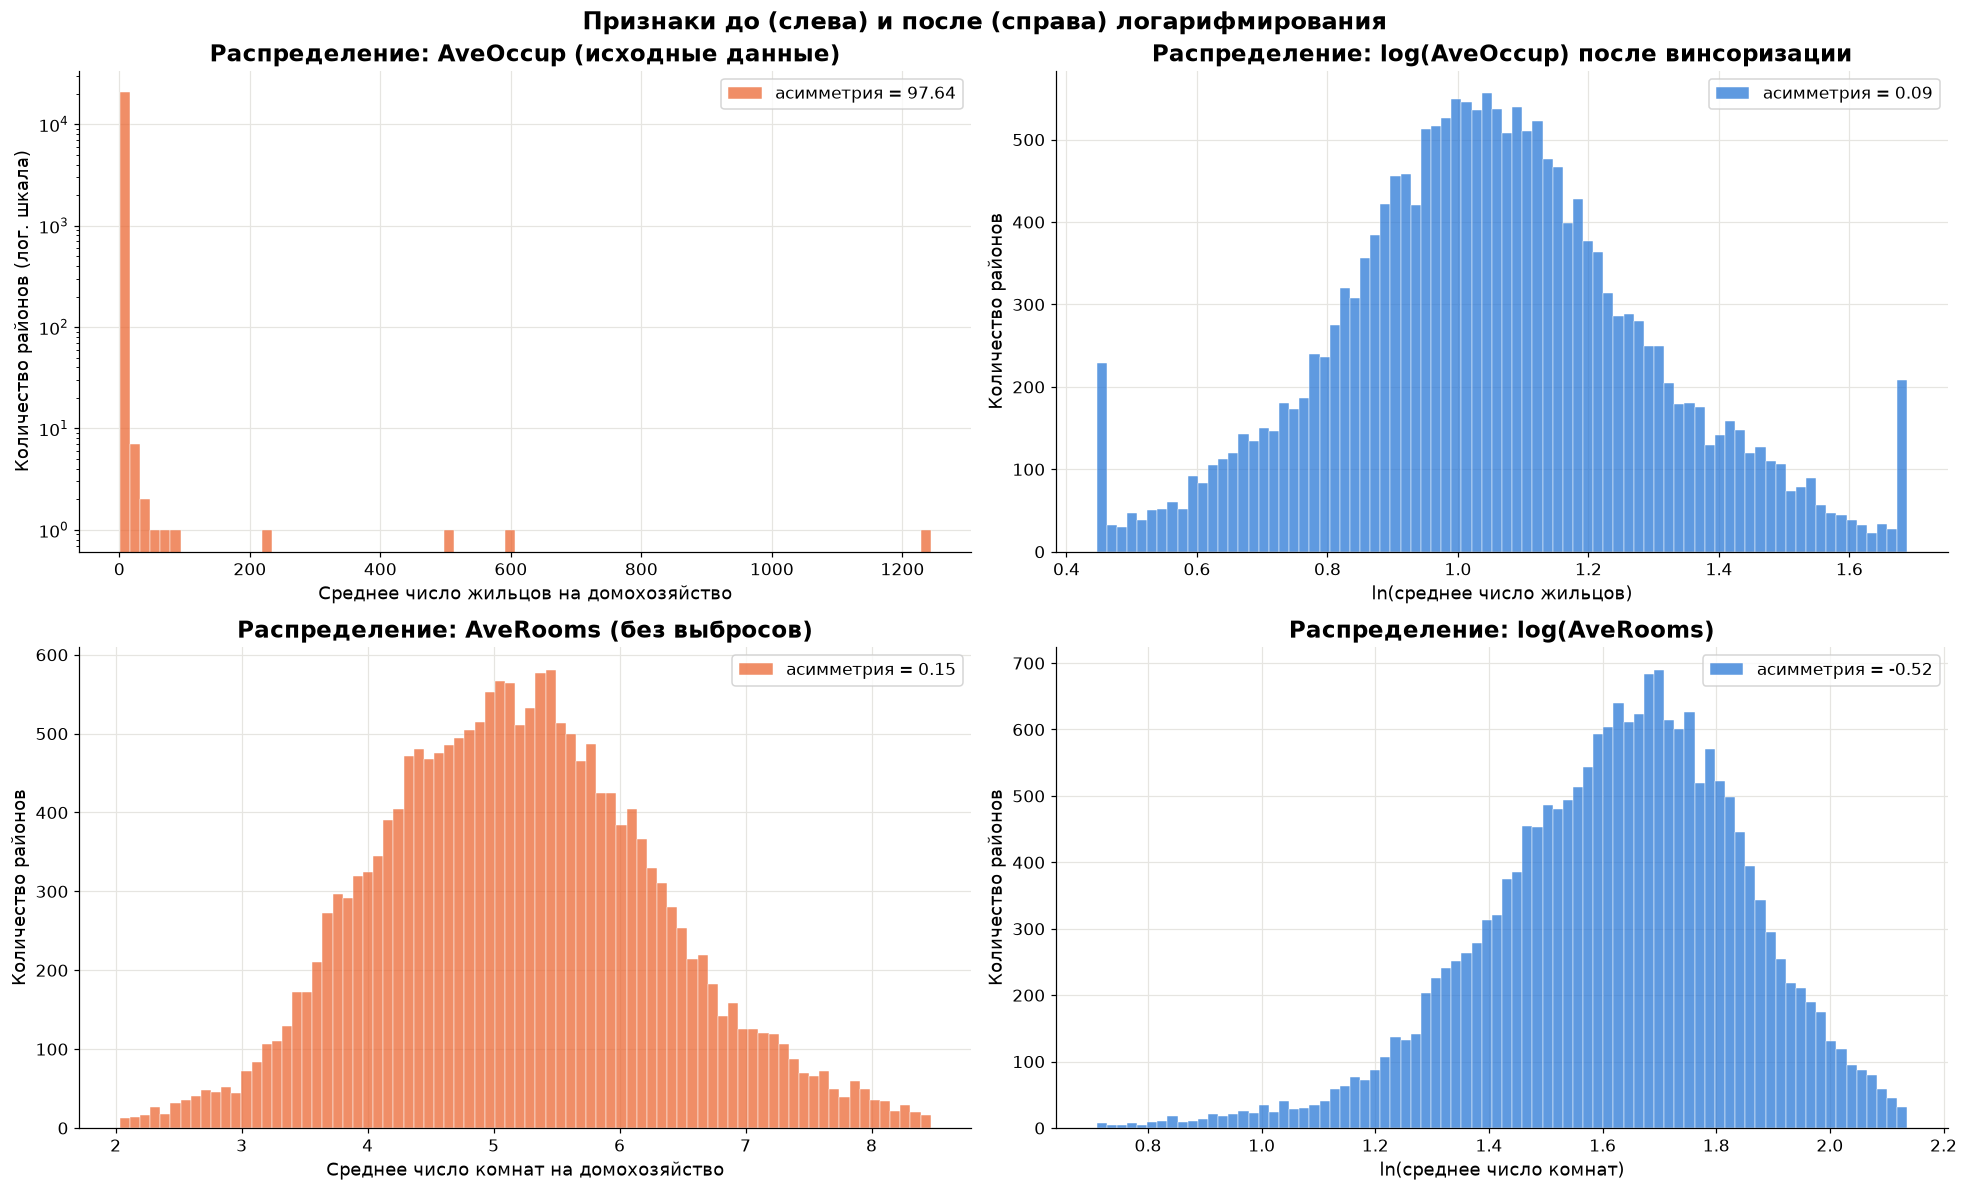

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

pairs = [
    (df["AveOccup"], "AveOccup (исходные данные)", "Среднее число жильцов на домохозяйство", ORANGE),
    (df_transformed["log_AveOccup"], "log(AveOccup) после винсоризации", "ln(среднее число жильцов)", BLUE),
    (df_clean["AveRooms"], "AveRooms (без выбросов)", "Среднее число комнат на домохозяйство", ORANGE),
    (df_transformed["log_AveRooms"], "log(AveRooms)", "ln(среднее число комнат)", BLUE),
]
for ax, (series, title, xlabel, color) in zip(axes.flat, pairs):
    sns.histplot(series, bins=80, color=color, edgecolor="white", linewidth=0.3, ax=ax,
                 label=f"асимметрия = {series.skew():.2f}")
    ax.set_title(f"Распределение: {title}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Количество районов")
    ax.legend(loc="upper right")
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel("Количество районов (лог. шкала)")
fig.suptitle("Признаки до (слева) и после (справа) логарифмирования", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

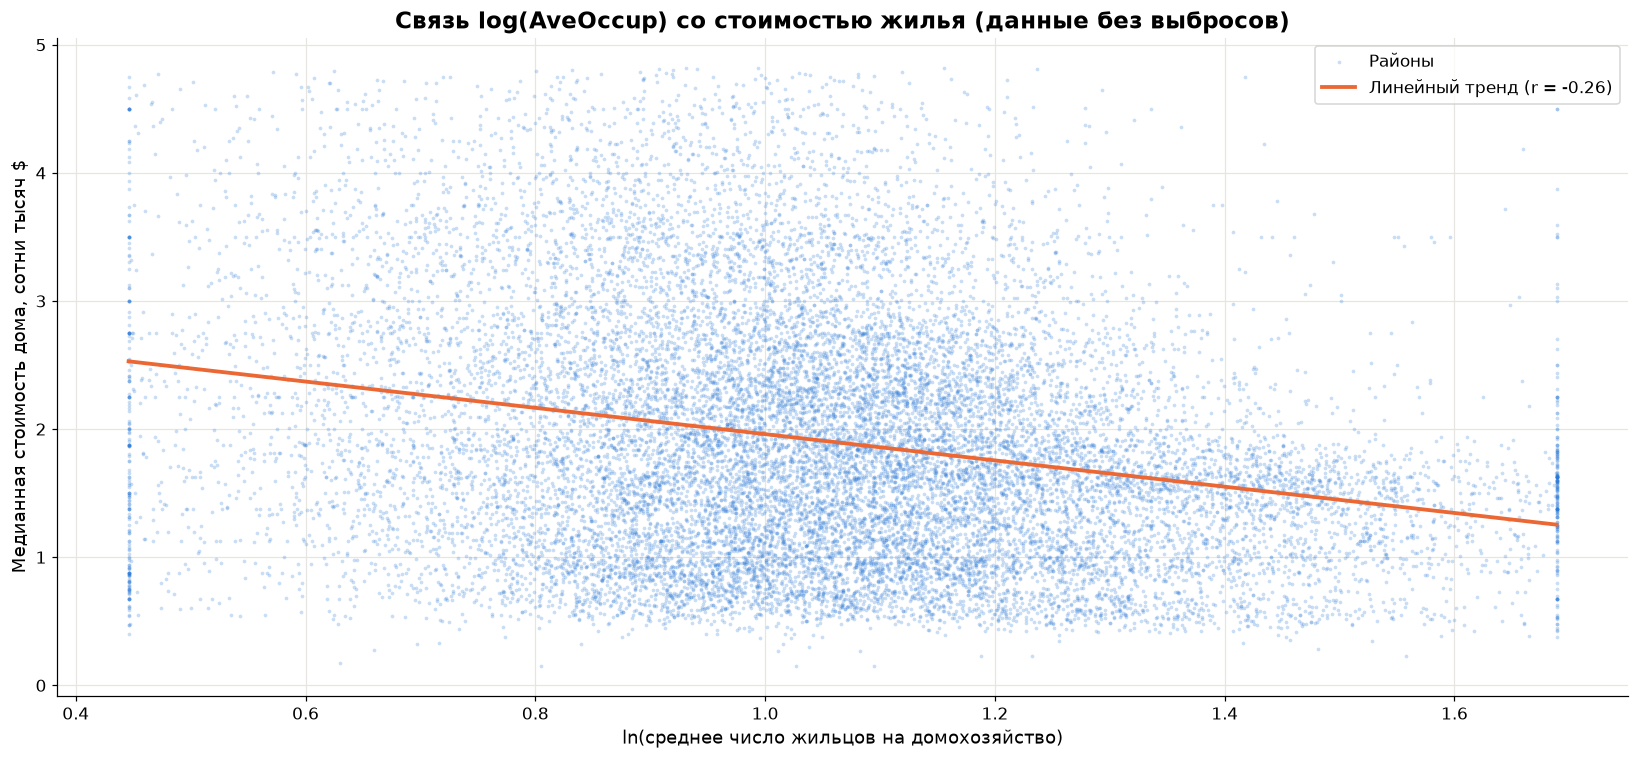

In [23]:
fig, ax = plt.subplots(figsize=(15, 7))
ax.scatter(df_transformed["log_AveOccup"], df_transformed[TARGET], s=6, alpha=0.25, color=BLUE,
           linewidths=0, label="Районы")
coef = np.polyfit(df_transformed["log_AveOccup"], df_transformed[TARGET], 1)
x_line = np.linspace(*occup_bounds, 100)
ax.plot(x_line, np.polyval(coef, x_line), color=ORANGE, lw=2.5,
        label=f"Линейный тренд (r = {df_transformed['log_AveOccup'].corr(df_transformed[TARGET]):.2f})")
ax.set_title("Связь log(AveOccup) со стоимостью жилья (данные без выбросов)")
ax.set_xlabel("ln(среднее число жильцов на домохозяйство)")
ax.set_ylabel("Медианная стоимость дома, сотни тысяч $")
ax.legend()
plt.tight_layout()
plt.show()

**Что показали преобразования:**
- У `AveOccup` за выбросами действительно скрывалась связь: после логарифмирования и винсоризации |r| вырос примерно в 10 раз — с −0.03 до −0.26. Чем больше жильцов на одно домохозяйство (плотнее заселение), тем дешевле жильё. Удаление этого признака в п. 6 было следствием того, что корреляция Пирсона на сырых данных с выбросами ввела в заблуждение — хороший пример, почему EDA нужно проводить итеративно.
- У `AveRooms` после удаления выбросов распределение уже почти симметрично (асимметрия 0.15), поэтому от логарифма ждём лишь небольшого эффекта — за счёт убывающего влияния числа комнат.

Посмотрим, какой вклад вносит каждое преобразование (на тех же данных, что и Модель 3):

In [24]:
features_model_4 = ["MedInc", "HouseAge", "log_AveRooms", "Latitude", "Longitude",
                    "Latitude_sq", "Longitude_sq", "Lat_x_Lon"]
features_model_5 = features_model_4 + ["log_AveOccup"]

steps = {
    "Модель 3 (без преобразований)": features_selected,
    "+ log(AveRooms) вместо AveRooms": ["MedInc", "HouseAge", "log_AveRooms", "Latitude", "Longitude"],
    "+ Latitude², Longitude², Latitude·Longitude": features_model_4,
    "+ log(AveOccup)": features_model_5,
}
ablation = pd.DataFrame(
    [(name, *quick_test_score(df_transformed, feats)) for name, feats in steps.items()],
    columns=["Шаг", "RMSE test", "R2 test"],
).set_index("Шаг")
ablation.round(4)

,RMSE test,R2 test
Шаг,,
Модель 3 (без преобразований),0.6089,0.5925
+ log(AveRooms) вместо AveRooms,0.6071,0.5948
"+ Latitude², Longitude², Latitude·Longitude",0.5957,0.6100
+ log(AveOccup),0.5522,0.6649


In [25]:
model_4 = fit_and_evaluate(
    df_transformed, features_model_4,
    model_name="Модель 4. Математические преобразования отобранных признаков",
    short_name="М4. + преобразования",
    description="MedInc, HouseAge, log(AveRooms), Latitude, Longitude, Latitude², Longitude², "
                "Latitude·Longitude; данные без выбросов",
)
print()
model_5 = fit_and_evaluate(
    df_transformed, features_model_5,
    model_name="Модель 5. Преобразования + возвращённый log(AveOccup)",
    short_name="М5. + log(AveOccup)",
    description="Признаки Модели 4 + log(AveOccup) с винсоризацией по 1-му и 99-му перцентилям; "
                "данные без выбросов",
)

Модель 4. Математические преобразования отобранных признаков
  Обучающая выборка:  15336 объектов | RMSE = 0.6121 | R² = 0.5861
  Тестовая выборка:    3834 объектов | RMSE = 0.5957 | R² = 0.6100

Модель 5. Преобразования + возвращённый log(AveOccup)
  Обучающая выборка:  15336 объектов | RMSE = 0.5711 | R² = 0.6396
  Тестовая выборка:    3834 объектов | RMSE = 0.5522 | R² = 0.6649


**Вывод по п. 8:**
- `log(AveRooms)` дал небольшое улучшение (RMSE 0.6089 → 0.6071).
- Полином 2-й степени от координат — заметное: R² на тесте вырос до 0.6100 (**Модель 4**), модель лучше описывает географию цен.
- Возвращение `AveOccup` в логарифмической форме дало самый большой прирост: RMSE 0.5957 → 0.5522, R² 0.6100 → 0.6649 (**Модель 5**).
- Разрыв между train и test остаётся небольшим (R² 0.6396 и 0.6649), признаков переобучения нет.

## 9. Выводы по проделанной работе

### 9a. Какие преобразования были сделаны с данными
1. **Пропуски и дубликаты** — проверены, не обнаружены.
2. **Отбор признаков по корреляционной матрице** — удалены `Population` и `AveOccup` (нет линейной связи с целевой) и `AveBedrms` (мультиколлинеарность с `AveRooms`, r = 0.85). Обе координаты оставлены: они информативны в паре.
3. **Удаление выбросов** — по правилу Тьюки: `MedHouseVal` (включая цензурированные 5.00001) и `AveRooms` — за пределами 1.5·IQR, `MedInc` — только экстремальные, за пределами 3·IQR. Удалено 1 470 строк (7.1 %).
4. **Математические преобразования** — логарифм `AveRooms`; квадраты и произведение координат (`Latitude²`, `Longitude²`, `Latitude·Longitude`); логарифм `AveOccup` с винсоризацией по 1-му и 99-му перцентилям (признак возвращён в модель после того, как логарифмирование выявило скрытую связь).

### 9b. Сравнение метрик всех моделей

In [26]:
summary = pd.DataFrame(results).T
summary.index.name = "Модель"
summary = summary.drop(columns="Модель")
num_cols = ["RMSE train", "R2 train", "RMSE test", "R2 test"]
summary[num_cols] = summary[num_cols].astype(float).round(4)
summary

,RMSE train,R2 train,RMSE test,R2 test,Объектов,Признаков,Признаки (преобразования)
Модель,,,,,,,
М1. Все признаки,0.7197,0.6126,0.7456,0.5758,20640,8,"Все 8 признаков без изменений: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude"
М2. Отбор по корреляции,0.7327,0.5985,0.7407,0.5814,20640,5,"MedInc, HouseAge, AveRooms, Latitude, Longitude — без изменений (удалены AveBedrms, Population, AveOccup)"
М3. + без выбросов,0.6252,0.5682,0.6089,0.5925,19170,5,"MedInc, HouseAge, AveRooms, Latitude, Longitude без изменений; удалены выбросы: MedHouseVal и AveRooms — по 1.5·IQR, MedInc — по 3·IQR (−1 470 строк)"
М4. + преобразования,0.6121,0.5861,0.5957,0.6100,19170,8,"MedInc, HouseAge, log(AveRooms), Latitude, Longitude, Latitude², Longitude², Latitude·Longitude; данные без выбросов"
М5. + log(AveOccup),0.5711,0.6396,0.5522,0.6649,19170,9,Признаки Модели 4 + log(AveOccup) с винсоризацией по 1-му и 99-му перцентилям; данные без выбросов


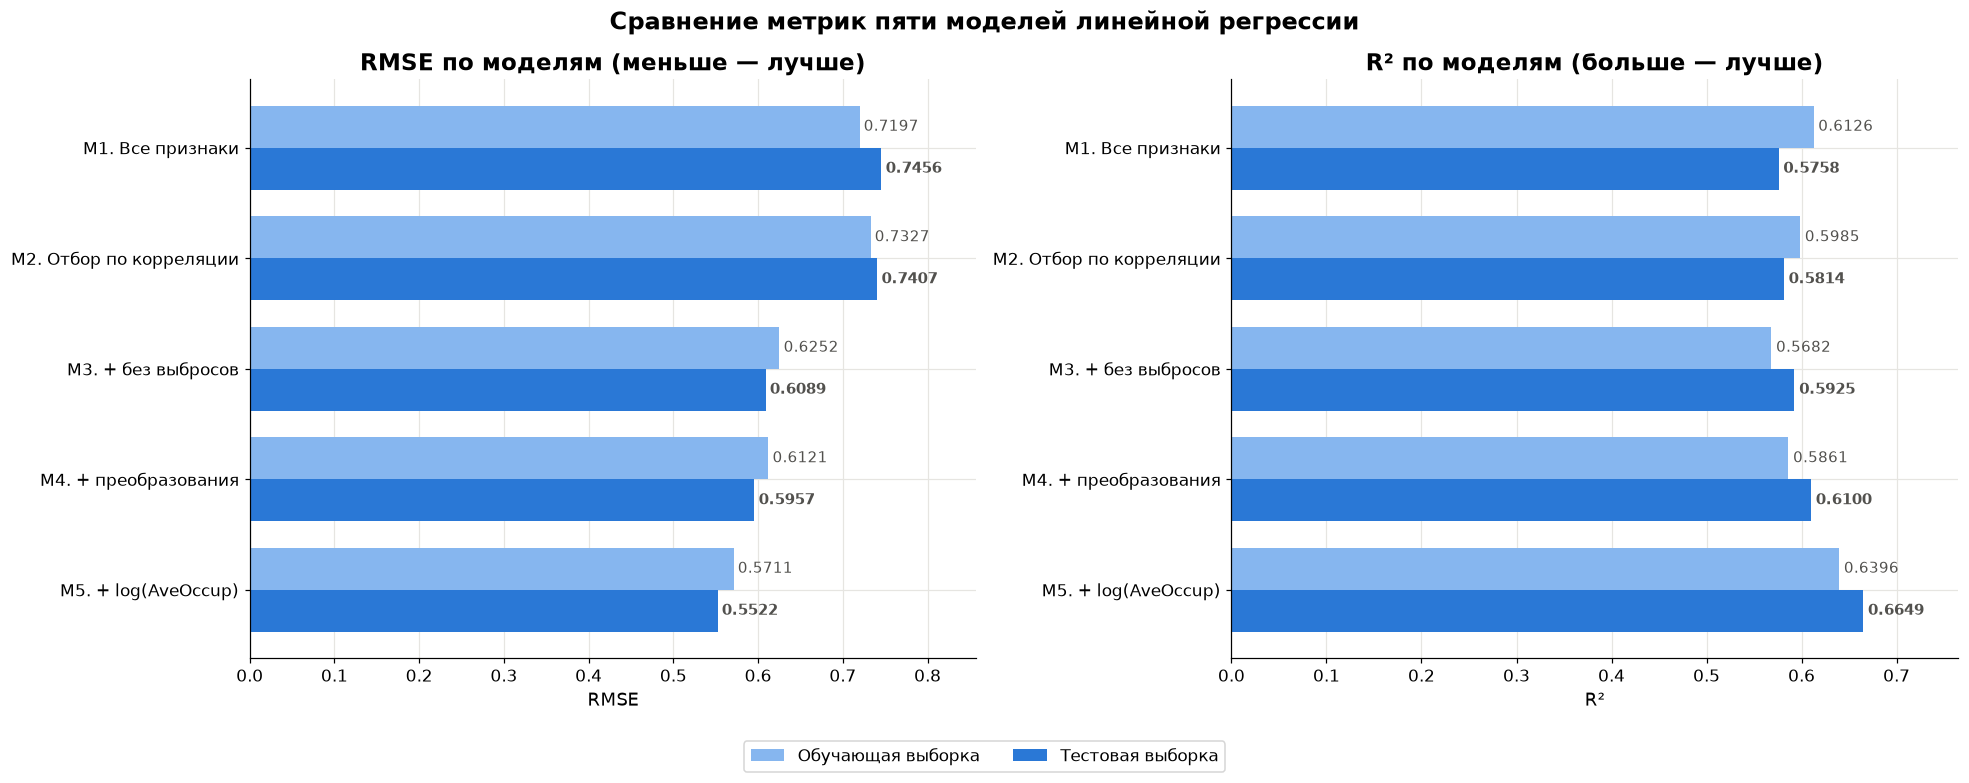

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
names = list(summary.index)
y_pos = np.arange(len(names))
h = 0.38

for ax, metric, title, better in [
    (axes[0], "RMSE", "RMSE по моделям (меньше — лучше)", "min"),
    (axes[1], "R2", "R² по моделям (больше — лучше)", "max"),
]:
    tr, te = summary[f"{metric} train"], summary[f"{metric} test"]
    ax.barh(y_pos - h / 2, tr, height=h, color="#86b6ef", label="Обучающая выборка")
    ax.barh(y_pos + h / 2, te, height=h, color=BLUE, label="Тестовая выборка")
    for i, (a, b) in enumerate(zip(tr, te)):
        ax.text(a + 0.005, i - h / 2, f"{a:.4f}", va="center", fontsize=10, color=INK)
        ax.text(b + 0.005, i + h / 2, f"{b:.4f}", va="center", fontsize=10, color=INK, fontweight="bold")
    ax.set_yticks(y_pos, names)
    ax.invert_yaxis()
    ax.set_xlim(0, max(tr.max(), te.max()) * 1.15)
    ax.set_title(title)
    ax.set_xlabel(metric.replace("R2", "R²"))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Сравнение метрик пяти моделей линейной регрессии", fontsize=16, fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

| Модель | RMSE test | R² test | Объектов | Признаки, на которых проводилось обучение (с указанием преобразований) |
|---|---|---|---|---|
| М1. Все признаки | 0.7456 | 0.5758 | 20 640 | `MedInc`, `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, `Longitude` — без изменений |
| М2. Отбор по корреляции | 0.7407 | 0.5814 | 20 640 | `MedInc`, `HouseAge`, `AveRooms`, `Latitude`, `Longitude` — без изменений |
| М3. + без выбросов | 0.6089 | 0.5925 | 19 170 | те же 5 признаков; удалены выбросы `MedHouseVal`, `AveRooms` (1.5·IQR) и `MedInc` (3·IQR) |
| М4. + преобразования | 0.5957 | 0.6100 | 19 170 | `MedInc`, `HouseAge`, **log(`AveRooms`)**, `Latitude`, `Longitude`, **`Latitude²`, `Longitude²`, `Latitude·Longitude`**; без выбросов |
| М5. + log(AveOccup) | **0.5522** | **0.6649** | 19 170 | признаки Модели 4 + **log(`AveOccup`)** с винсоризацией 1–99 %; без выбросов |

Итог: от Модели 1 к Модели 5 RMSE на тестовой выборке снизился с 0.7456 до 0.5522 (на 26 %), R² вырос с 0.5758 до 0.6649 (+0.089).

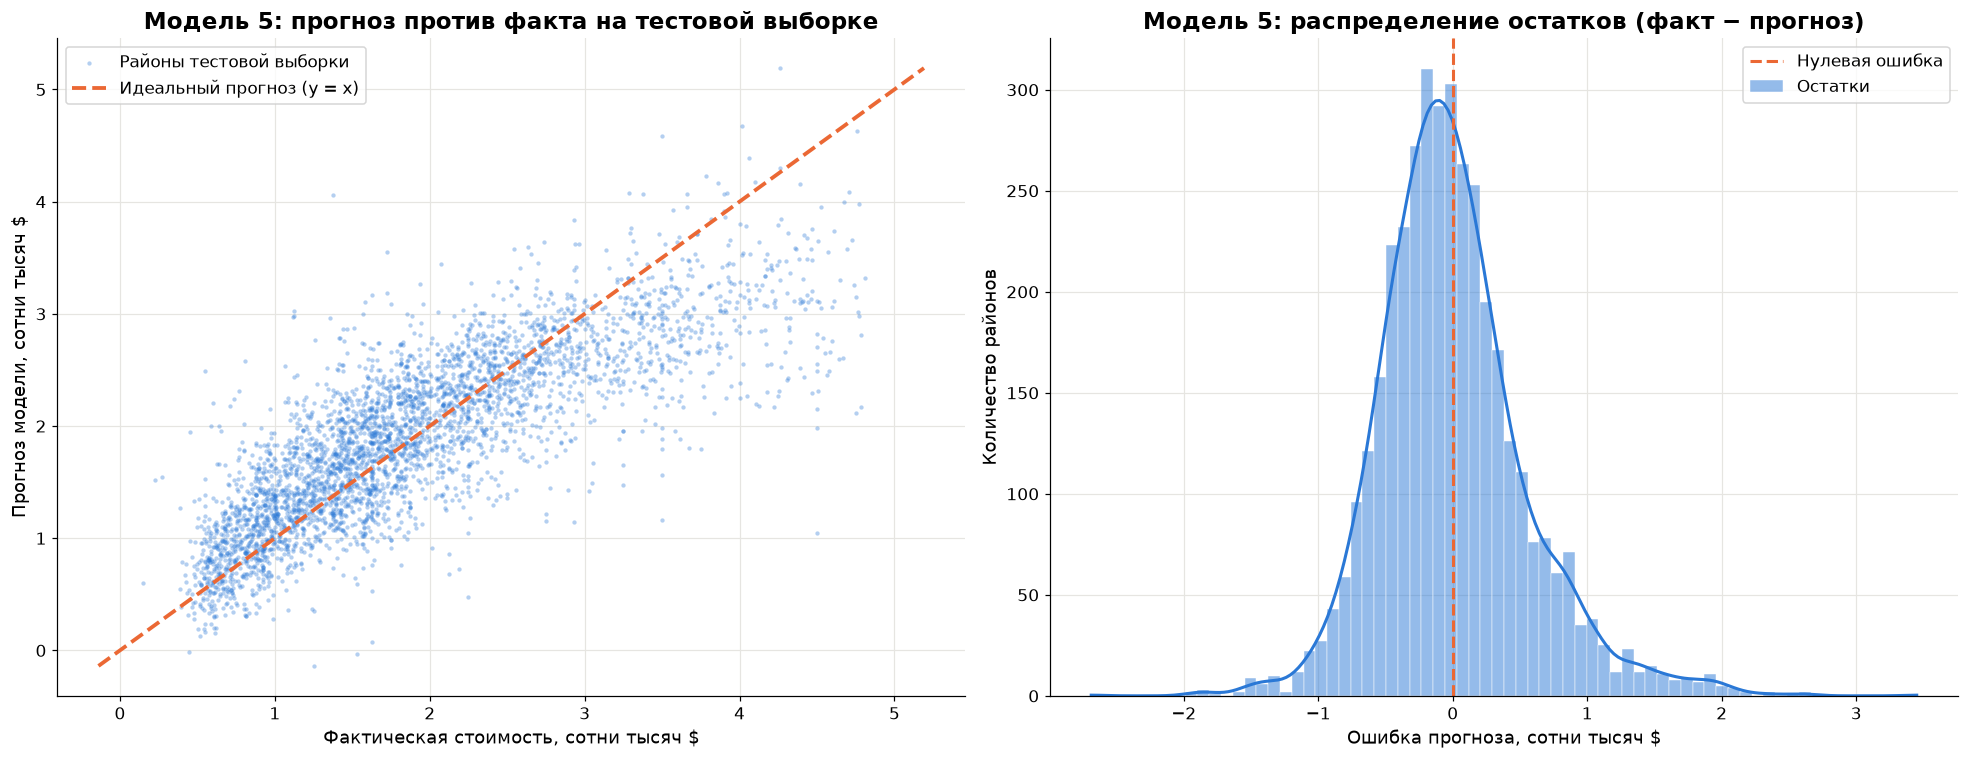

Средняя абсолютная ошибка Модели 5: 0.410 (≈ 41 тыс. $)
Медианная стоимость на тесте: 1.706 (≈ 171 тыс. $)


In [28]:
y_test_5, pred_5 = model_5["y_test"], model_5["pred_test"]
residuals = y_test_5 - pred_5

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ax = axes[0]
ax.scatter(y_test_5, pred_5, s=8, alpha=0.35, color=BLUE, linewidths=0, label="Районы тестовой выборки")
lims = [min(y_test_5.min(), pred_5.min()), max(y_test_5.max(), pred_5.max())]
ax.plot(lims, lims, color=ORANGE, lw=2.5, ls="--", label="Идеальный прогноз (y = x)")
ax.set_title("Модель 5: прогноз против факта на тестовой выборке")
ax.set_xlabel("Фактическая стоимость, сотни тысяч $")
ax.set_ylabel("Прогноз модели, сотни тысяч $")
ax.legend(loc="upper left")

ax = axes[1]
sns.histplot(residuals, bins=70, kde=True, color=BLUE, edgecolor="white", linewidth=0.3,
             line_kws={"linewidth": 2}, ax=ax, label="Остатки")
ax.axvline(0, color=ORANGE, lw=2, ls="--", label="Нулевая ошибка")
ax.set_title("Модель 5: распределение остатков (факт − прогноз)")
ax.set_xlabel("Ошибка прогноза, сотни тысяч $")
ax.set_ylabel("Количество районов")
ax.legend()

plt.tight_layout()
plt.show()

print(f"Средняя абсолютная ошибка Модели 5: {np.abs(residuals).mean():.3f} (≈ {np.abs(residuals).mean() * 100:.0f} тыс. $)")
print(f"Медианная стоимость на тесте: {y_test_5.median():.3f} (≈ {y_test_5.median() * 100:.0f} тыс. $)")

### 9c. Справились ли модели с задачей

**Цель задания достигнута:** за счёт работы с данными метрики линейной регрессии последовательно улучшались — R² на тесте вырос с 0.58 до 0.66, RMSE снизился на четверть. Каждый этап EDA внёс вклад, а самым полезным оказался не отбор признаков, а их **преобразования**: полином от координат и логарифм `AveOccup`.

**Но в полной мере с задачей прогнозирования модели не справились:**
- R² = 0.66 означает, что треть дисперсии стоимости модель не объясняет.
- Типичная ошибка ≈ 55 тыс. $ при медианной стоимости около 170 тыс. $ — это около трети цены, для практической оценки недвижимости много.
- На графике «прогноз против факта» видна систематическая ошибка: дешёвые районы модель переоценивает, дорогие — недооценивает (точки отклоняются от диагонали по краям). Это признак того, что зависимость стоимости от признаков нелинейная.

**Причины:** линейная модель не улавливает локальные географические эффекты (цены меняются скачками между соседними районами) и сложные взаимодействия признаков; данные агрегированы по районам; верхняя часть цен цензурирована.

**Что можно сделать дальше:** логарифмировать целевую переменную; построить географические признаки (расстояние до побережья и крупных городов, кластеры районов); добавить полиномиальные признаки с регуляризацией (Ridge/Lasso); попробовать нелинейные модели — ансамбли деревьев решений на этом датасете обычно заметно превосходят линейную регрессию.

## 10. Дополнительная проверка на исходной тестовой выборке

**Важная оговорка к сравнению выше.** По условию задания после удаления выбросов разбиение выполняется заново, поэтому тестовые выборки Моделей 3–5 отличаются от тестовой выборки Моделей 1–2: в них нет дорогих и цензурированных районов, на которых ошибки самые большие. Часть «улучшения» RMSE — это эффект более лёгкого теста.

Чтобы сравнение было честным, повторим эксперимент иначе:
1. разбиваем **исходные** данные так же, как для Модели 1 (`random_state=42`);
2. границы выбросов и винсоризации считаем **только по обучающей части**;
3. выбросы удаляем **только из обучающей выборки**;
4. все модели оцениваем на одной и той же **исходной тестовой выборке** (4 128 районов), а также на её части без выбросов.

In [29]:
train_raw, test_raw = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)

# Границы выбросов — только по обучающей части
train_bounds = {col: iqr_bounds(train_raw[col], k) for col, k in outlier_rules.items()}


def outlier_mask(data):
    m = pd.Series(True, index=data.index)
    for col, (lo, hi) in train_bounds.items():
        m &= data[col].between(lo, hi)
    return m


train_clean = train_raw[outlier_mask(train_raw)]
test_clean = test_raw[outlier_mask(test_raw)]
print(f"Обучающая выборка: {len(train_raw)} → после удаления выбросов {len(train_clean)}")
print(f"Тестовая выборка: {len(test_raw)} (вся), из них без выбросов {len(test_clean)}")


def evaluate_on_original_test(name, features, train_data):
    bounds = tuple(np.log(train_data["AveOccup"]).quantile([0.01, 0.99]))
    tr = add_transformed_features(train_data, bounds)
    te_full = add_transformed_features(test_raw, bounds)
    te_clean = add_transformed_features(test_clean, bounds)
    model = LinearRegression().fit(tr[features], tr[TARGET])
    p_full, p_clean = model.predict(te_full[features]), model.predict(te_clean[features])
    return {
        "Модель": name,
        "Обучение": "train без выбросов" if len(train_data) < len(train_raw) else "весь train",
        "RMSE (весь test)": rmse(te_full[TARGET], p_full),
        "R2 (весь test)": r2_score(te_full[TARGET], p_full),
        "RMSE (test без выбросов)": rmse(te_clean[TARGET], p_clean),
        "R2 (test без выбросов)": r2_score(te_clean[TARGET], p_clean),
    }


honest = pd.DataFrame([
    evaluate_on_original_test("М1. Все признаки", features_all, train_raw),
    evaluate_on_original_test("М2. Отбор по корреляции", features_selected, train_raw),
    evaluate_on_original_test("М3. + без выбросов", features_selected, train_clean),
    evaluate_on_original_test("М4. + преобразования", features_model_4, train_clean),
    evaluate_on_original_test("М5. + log(AveOccup)", features_model_5, train_clean),
    evaluate_on_original_test("М5* — признаки М5, выбросы не удалялись", features_model_5, train_raw),
]).set_index("Модель")
honest.round(4)

Обучающая выборка: 16512 → после удаления выбросов 15321
Тестовая выборка: 4128 (вся), из них без выбросов 3852


,Обучение,RMSE (весь test),R2 (весь test),RMSE (test без выбросов),R2 (test без выбросов)
Модель,,,,,
М1. Все признаки,весь train,0.7456,0.5758,0.6236,0.5762
М2. Отбор по корреляции,весь train,0.7407,0.5814,0.6376,0.5570
М3. + без выбросов,train без выбросов,0.7838,0.5311,0.6291,0.5687
М4. + преобразования,train без выбросов,0.7334,0.5896,0.6141,0.5890
М5. + log(AveOccup),train без выбросов,0.6782,0.6490,0.5728,0.6424
"М5* — признаки М5, выбросы не удалялись",весь train,0.6680,0.6595,0.5801,0.6332


**Выводы по честной проверке:**
- **Удаление выбросов само по себе модель не улучшило.** На полной тестовой выборке Модель 3 хуже Модели 2 (RMSE 0.7838 против 0.7407): модель, не видевшая дорогих районов, систематически их недооценивает. Даже на тестовых районах без выбросов Модель 3 не лучше Модели 1 (RMSE 0.6291 против 0.6236). Значит, снижение RMSE в п. 7 в основном объясняется более «лёгкой» тестовой выборкой.
- **Математические преобразования дают реальное улучшение.** Модель 5 лучше Модели 1 на обоих вариантах теста: на полном — RMSE 0.7456 → 0.6782, R² 0.5758 → 0.6490; на части без выбросов — RMSE 0.6236 → 0.5728.
- **Выбор зависит от задачи.** Если модель должна оценивать все районы, выбросы лучше не удалять, а только преобразовать признаки: Модель 5* показывает лучший результат на полном тесте (R² 0.6595). Если дорогие и цензурированные районы вне рамок задачи (например, оценка массового жилья), модель, обученная на очищенных данных, немного точнее на типичных объектах (RMSE 0.5728 против 0.5801).

Главный практический вывод работы: EDA нужно проводить итеративно и проверять каждое решение на неизменной тестовой выборке — иначе легко принять «облегчение» теста за улучшение модели.